# CNN-Based Weapon-in-Hand Detection System for School CCTV
Classes: harmless_object, melee, ranged, student

**C3: Optimizer: SGD**

3 Conv2D (32, 64, 128) + 3 MaxPooling2D, Dense 128, relu / softmax, 150x150, batch 32, 4 epochs, sgd

In [1]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [2]:
# Construct an instance of ImageDataGenerator class
# rescale = 1./255 normalizes the pixel values from 0-255 to 0-1
train_datagen = ImageDataGenerator(rescale = 1./255)
test_datagen = ImageDataGenerator(rescale = 1./255)

In [3]:
# Use flow_from_directory to take the path and generate batches of data
train_iterator = train_datagen.flow_from_directory(
    'dataset/train',
    target_size=(150, 150),
    batch_size=32,
    class_mode='categorical'
)

test_iterator = test_datagen.flow_from_directory(
    'dataset/test',
    target_size=(150, 150),
    batch_size=32,
    class_mode='categorical'
)

Found 15803 images belonging to 4 classes.
Found 880 images belonging to 4 classes.


In [4]:
# Defining the sequential model for weapon-in-hand classification
model = keras.Sequential()

# Convolution and Pooling Layers
model.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(150, 150, 3)))
model.add(layers.MaxPooling2D((2, 2)))

model.add(layers.Conv2D(64, (3, 3), activation='relu'))
model.add(layers.MaxPooling2D((2, 2)))

model.add(layers.Conv2D(128, (3, 3), activation='relu'))
model.add(layers.MaxPooling2D((2, 2)))

# Core Layers
model.add(layers.Flatten())
model.add(layers.Dense(128, activation='relu'))

# Output layer: 4 nodes with softmax (harmless_object, melee, ranged, student)
model.add(layers.Dense(4, activation='softmax'))

In [5]:
# Compile and fit the model
model.compile(loss='categorical_crossentropy', optimizer='sgd', metrics=['accuracy'])

history = model.fit(train_iterator, validation_data=test_iterator, epochs=4)

Epoch 1/4
494/494 [==============================] - 158s 319ms/step - loss: 1.3713 - accuracy: 0.3018 - val_loss: 1.2897 - val_accuracy: 0.4307
Epoch 2/4
494/494 [==============================] - 168s 341ms/step - loss: 1.2623 - accuracy: 0.4176 - val_loss: 1.1440 - val_accuracy: 0.5227
Epoch 3/4
494/494 [==============================] - 173s 351ms/step - loss: 1.1497 - accuracy: 0.4925 - val_loss: 1.0661 - val_accuracy: 0.5625
Epoch 4/4
494/494 [==============================] - 173s 349ms/step - loss: 1.0896 - accuracy: 0.5293 - val_loss: 0.9982 - val_accuracy: 0.6114


In [6]:
# Evaluating the Model using test data
model.evaluate(test_iterator)

28/28 [==============================] - 4s 147ms/step - loss: 0.9982 - accuracy: 0.6114


[0.9982352256774902, 0.6113636493682861]

In [7]:
# Saving Model
model.save('WeaponCNN.h5')

In [8]:
# get the class labels from iterator
labels = train_iterator.class_indices
print(labels)

{'harmless_object': 0, 'melee': 1, 'ranged': 2, 'student': 3}


## Prediction

In [9]:
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import load_img, img_to_array
import matplotlib.pyplot as plt
import numpy as np

In [10]:
# load the saved model
model = load_model('WeaponCNN.h5')

# class labels from the iterator
labels = ['harmless_object', 'melee', 'ranged', 'student']

# TYPICAL PHOTOS TEST
Photos from `dataset/test/` in the most common style of each class (not used in training)

## student_0035.jpg
Actual: student

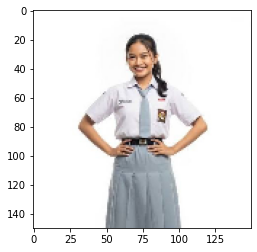

[[0.52634794 0.2013047  0.11070056 0.16164678]]
harmless_object


In [11]:
# load an image for prediction
img = load_img('dataset/test/student/student_0035.jpg', target_size=(150, 150))
plt.imshow(img)
plt.show()

# convert img to array and add dimension
img = img_to_array(img)
img = img.reshape(1, 150, 150, 3)
img = img / 255

# getting the prediction
result = model.predict(img)
print(result)
confidence = np.max(result)
result = np.argmax(result)

if result == 0:
    print(labels[0])
elif result == 1:
    print(labels[1])
    print('ALERT: melee weapon detected, confidence', confidence)
elif result == 2:
    print(labels[2])
    print('ALERT: ranged weapon detected, confidence', confidence)
elif result == 3:
    print(labels[3])

## student_0232.jpg
Actual: student

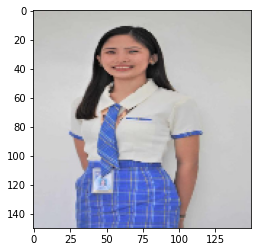

[[0.24914905 0.02696254 0.028526   0.6953624 ]]
student


In [12]:
# load an image for prediction
img = load_img('dataset/test/student/student_0232.jpg', target_size=(150, 150))
plt.imshow(img)
plt.show()

# convert img to array and add dimension
img = img_to_array(img)
img = img.reshape(1, 150, 150, 3)
img = img / 255

# getting the prediction
result = model.predict(img)
print(result)
confidence = np.max(result)
result = np.argmax(result)

if result == 0:
    print(labels[0])
elif result == 1:
    print(labels[1])
    print('ALERT: melee weapon detected, confidence', confidence)
elif result == 2:
    print(labels[2])
    print('ALERT: ranged weapon detected, confidence', confidence)
elif result == 3:
    print(labels[3])

## harmless_object_0302.jpg
Actual: harmless_object

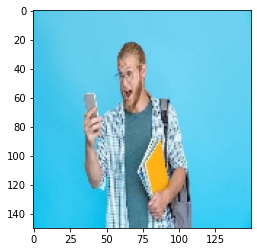

[[0.80714095 0.04579119 0.04856665 0.09850125]]
harmless_object


In [13]:
# load an image for prediction
img = load_img('dataset/test/harmless_object/harmless_object_0302.jpg', target_size=(150, 150))
plt.imshow(img)
plt.show()

# convert img to array and add dimension
img = img_to_array(img)
img = img.reshape(1, 150, 150, 3)
img = img / 255

# getting the prediction
result = model.predict(img)
print(result)
confidence = np.max(result)
result = np.argmax(result)

if result == 0:
    print(labels[0])
elif result == 1:
    print(labels[1])
    print('ALERT: melee weapon detected, confidence', confidence)
elif result == 2:
    print(labels[2])
    print('ALERT: ranged weapon detected, confidence', confidence)
elif result == 3:
    print(labels[3])

## harmless_object_0321.jpg
Actual: harmless_object

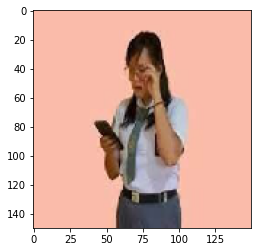

[[0.6314477  0.04763964 0.07875727 0.24215531]]
harmless_object


In [14]:
# load an image for prediction
img = load_img('dataset/test/harmless_object/harmless_object_0321.jpg', target_size=(150, 150))
plt.imshow(img)
plt.show()

# convert img to array and add dimension
img = img_to_array(img)
img = img.reshape(1, 150, 150, 3)
img = img / 255

# getting the prediction
result = model.predict(img)
print(result)
confidence = np.max(result)
result = np.argmax(result)

if result == 0:
    print(labels[0])
elif result == 1:
    print(labels[1])
    print('ALERT: melee weapon detected, confidence', confidence)
elif result == 2:
    print(labels[2])
    print('ALERT: ranged weapon detected, confidence', confidence)
elif result == 3:
    print(labels[3])

## melee_0107.jpg
Actual: melee

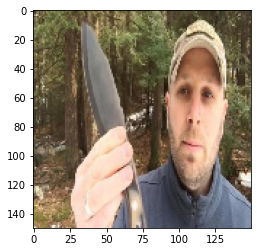

[[0.2998027  0.4037064  0.17432722 0.1221637 ]]
melee
ALERT: melee weapon detected, confidence 0.4037064


In [15]:
# load an image for prediction
img = load_img('dataset/test/melee/melee_0107.jpg', target_size=(150, 150))
plt.imshow(img)
plt.show()

# convert img to array and add dimension
img = img_to_array(img)
img = img.reshape(1, 150, 150, 3)
img = img / 255

# getting the prediction
result = model.predict(img)
print(result)
confidence = np.max(result)
result = np.argmax(result)

if result == 0:
    print(labels[0])
elif result == 1:
    print(labels[1])
    print('ALERT: melee weapon detected, confidence', confidence)
elif result == 2:
    print(labels[2])
    print('ALERT: ranged weapon detected, confidence', confidence)
elif result == 3:
    print(labels[3])

## melee_0155.jpg
Actual: melee

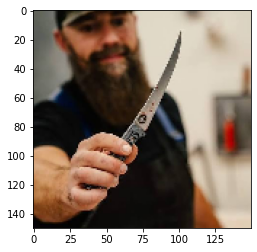

[[0.33014414 0.31763107 0.2851581  0.06706673]]
harmless_object


In [16]:
# load an image for prediction
img = load_img('dataset/test/melee/melee_0155.jpg', target_size=(150, 150))
plt.imshow(img)
plt.show()

# convert img to array and add dimension
img = img_to_array(img)
img = img.reshape(1, 150, 150, 3)
img = img / 255

# getting the prediction
result = model.predict(img)
print(result)
confidence = np.max(result)
result = np.argmax(result)

if result == 0:
    print(labels[0])
elif result == 1:
    print(labels[1])
    print('ALERT: melee weapon detected, confidence', confidence)
elif result == 2:
    print(labels[2])
    print('ALERT: ranged weapon detected, confidence', confidence)
elif result == 3:
    print(labels[3])

## ranged_0103.jpg
Actual: ranged

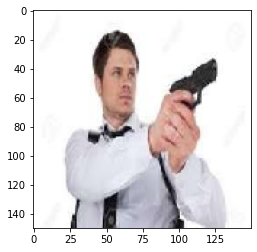

[[0.42385563 0.10772966 0.1991446  0.2692701 ]]
harmless_object


In [17]:
# load an image for prediction
img = load_img('dataset/test/ranged/ranged_0103.jpg', target_size=(150, 150))
plt.imshow(img)
plt.show()

# convert img to array and add dimension
img = img_to_array(img)
img = img.reshape(1, 150, 150, 3)
img = img / 255

# getting the prediction
result = model.predict(img)
print(result)
confidence = np.max(result)
result = np.argmax(result)

if result == 0:
    print(labels[0])
elif result == 1:
    print(labels[1])
    print('ALERT: melee weapon detected, confidence', confidence)
elif result == 2:
    print(labels[2])
    print('ALERT: ranged weapon detected, confidence', confidence)
elif result == 3:
    print(labels[3])

## ranged_0139.jpg
Actual: ranged

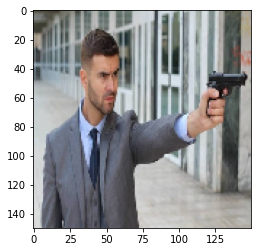

[[0.26026106 0.0914785  0.17203408 0.4762264 ]]
student


In [18]:
# load an image for prediction
img = load_img('dataset/test/ranged/ranged_0139.jpg', target_size=(150, 150))
plt.imshow(img)
plt.show()

# convert img to array and add dimension
img = img_to_array(img)
img = img.reshape(1, 150, 150, 3)
img = img / 255

# getting the prediction
result = model.predict(img)
print(result)
confidence = np.max(result)
result = np.argmax(result)

if result == 0:
    print(labels[0])
elif result == 1:
    print(labels[1])
    print('ALERT: melee weapon detected, confidence', confidence)
elif result == 2:
    print(labels[2])
    print('ALERT: ranged weapon detected, confidence', confidence)
elif result == 3:
    print(labels[3])

# OUR PHOTOS TEST
Our own photos from `my_photos_test/` (not used in training)

## student_test1.jpg
Actual: student

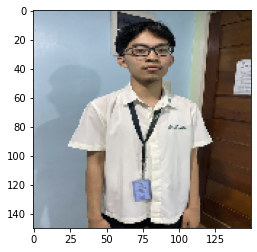

[[0.46788567 0.12511513 0.06021839 0.3467808 ]]
harmless_object


In [19]:
# load an image for prediction
img = load_img('my_photos_test/student_test1.jpg', target_size=(150, 150))
plt.imshow(img)
plt.show()

# convert img to array and add dimension
img = img_to_array(img)
img = img.reshape(1, 150, 150, 3)
img = img / 255

# getting the prediction
result = model.predict(img)
print(result)
confidence = np.max(result)
result = np.argmax(result)

if result == 0:
    print(labels[0])
elif result == 1:
    print(labels[1])
    print('ALERT: melee weapon detected, confidence', confidence)
elif result == 2:
    print(labels[2])
    print('ALERT: ranged weapon detected, confidence', confidence)
elif result == 3:
    print(labels[3])

## student_test2.jpg
Actual: student

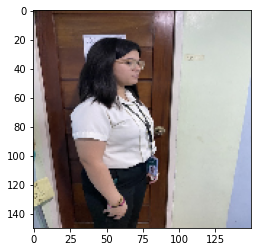

[[0.48646706 0.13003406 0.14291996 0.24057895]]
harmless_object


In [20]:
# load an image for prediction
img = load_img('my_photos_test/student_test2.jpg', target_size=(150, 150))
plt.imshow(img)
plt.show()

# convert img to array and add dimension
img = img_to_array(img)
img = img.reshape(1, 150, 150, 3)
img = img / 255

# getting the prediction
result = model.predict(img)
print(result)
confidence = np.max(result)
result = np.argmax(result)

if result == 0:
    print(labels[0])
elif result == 1:
    print(labels[1])
    print('ALERT: melee weapon detected, confidence', confidence)
elif result == 2:
    print(labels[2])
    print('ALERT: ranged weapon detected, confidence', confidence)
elif result == 3:
    print(labels[3])

## harmless_object_test1.jpg
Actual: harmless_object

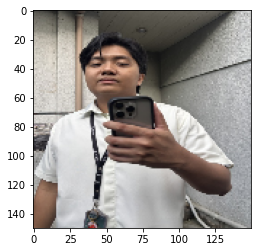

[[0.31740507 0.1665828  0.34071532 0.17529686]]
ranged
ALERT: ranged weapon detected, confidence 0.34071532


In [21]:
# load an image for prediction
img = load_img('my_photos_test/harmless_object_test1.jpg', target_size=(150, 150))
plt.imshow(img)
plt.show()

# convert img to array and add dimension
img = img_to_array(img)
img = img.reshape(1, 150, 150, 3)
img = img / 255

# getting the prediction
result = model.predict(img)
print(result)
confidence = np.max(result)
result = np.argmax(result)

if result == 0:
    print(labels[0])
elif result == 1:
    print(labels[1])
    print('ALERT: melee weapon detected, confidence', confidence)
elif result == 2:
    print(labels[2])
    print('ALERT: ranged weapon detected, confidence', confidence)
elif result == 3:
    print(labels[3])

## harmless_object_test2.jpg
Actual: harmless_object

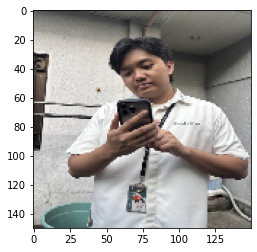

[[0.4540476  0.14328112 0.16769768 0.23497356]]
harmless_object


In [22]:
# load an image for prediction
img = load_img('my_photos_test/harmless_object_test2.jpg', target_size=(150, 150))
plt.imshow(img)
plt.show()

# convert img to array and add dimension
img = img_to_array(img)
img = img.reshape(1, 150, 150, 3)
img = img / 255

# getting the prediction
result = model.predict(img)
print(result)
confidence = np.max(result)
result = np.argmax(result)

if result == 0:
    print(labels[0])
elif result == 1:
    print(labels[1])
    print('ALERT: melee weapon detected, confidence', confidence)
elif result == 2:
    print(labels[2])
    print('ALERT: ranged weapon detected, confidence', confidence)
elif result == 3:
    print(labels[3])

## melee_test1.jpg
Actual: melee

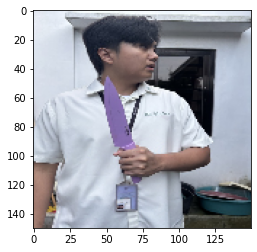

[[0.40735695 0.16791534 0.17070267 0.254025  ]]
harmless_object


In [23]:
# load an image for prediction
img = load_img('my_photos_test/melee_test1.jpg', target_size=(150, 150))
plt.imshow(img)
plt.show()

# convert img to array and add dimension
img = img_to_array(img)
img = img.reshape(1, 150, 150, 3)
img = img / 255

# getting the prediction
result = model.predict(img)
print(result)
confidence = np.max(result)
result = np.argmax(result)

if result == 0:
    print(labels[0])
elif result == 1:
    print(labels[1])
    print('ALERT: melee weapon detected, confidence', confidence)
elif result == 2:
    print(labels[2])
    print('ALERT: ranged weapon detected, confidence', confidence)
elif result == 3:
    print(labels[3])

## melee_test2.jpg
Actual: melee

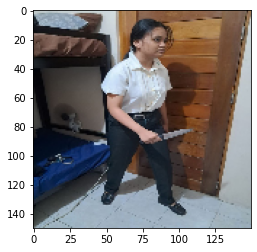

[[0.15874007 0.2952347  0.18231401 0.3637112 ]]
student


In [24]:
# load an image for prediction
img = load_img('my_photos_test/melee_test2.jpg', target_size=(150, 150))
plt.imshow(img)
plt.show()

# convert img to array and add dimension
img = img_to_array(img)
img = img.reshape(1, 150, 150, 3)
img = img / 255

# getting the prediction
result = model.predict(img)
print(result)
confidence = np.max(result)
result = np.argmax(result)

if result == 0:
    print(labels[0])
elif result == 1:
    print(labels[1])
    print('ALERT: melee weapon detected, confidence', confidence)
elif result == 2:
    print(labels[2])
    print('ALERT: ranged weapon detected, confidence', confidence)
elif result == 3:
    print(labels[3])

## ranged_test1.jpg
Actual: ranged

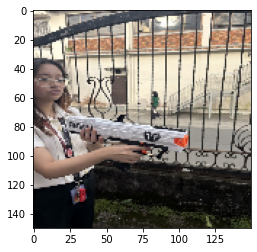

[[0.13293964 0.28500333 0.13685748 0.44519958]]
student


In [25]:
# load an image for prediction
img = load_img('my_photos_test/ranged_test1.jpg', target_size=(150, 150))
plt.imshow(img)
plt.show()

# convert img to array and add dimension
img = img_to_array(img)
img = img.reshape(1, 150, 150, 3)
img = img / 255

# getting the prediction
result = model.predict(img)
print(result)
confidence = np.max(result)
result = np.argmax(result)

if result == 0:
    print(labels[0])
elif result == 1:
    print(labels[1])
    print('ALERT: melee weapon detected, confidence', confidence)
elif result == 2:
    print(labels[2])
    print('ALERT: ranged weapon detected, confidence', confidence)
elif result == 3:
    print(labels[3])

## ranged_test2.jpg
Actual: ranged

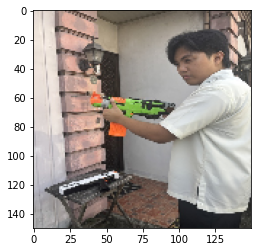

[[0.1942308  0.2957486  0.33613133 0.1738893 ]]
ranged
ALERT: ranged weapon detected, confidence 0.33613133


In [26]:
# load an image for prediction
img = load_img('my_photos_test/ranged_test2.jpg', target_size=(150, 150))
plt.imshow(img)
plt.show()

# convert img to array and add dimension
img = img_to_array(img)
img = img.reshape(1, 150, 150, 3)
img = img / 255

# getting the prediction
result = model.predict(img)
print(result)
confidence = np.max(result)
result = np.argmax(result)

if result == 0:
    print(labels[0])
elif result == 1:
    print(labels[1])
    print('ALERT: melee weapon detected, confidence', confidence)
elif result == 2:
    print(labels[2])
    print('ALERT: ranged weapon detected, confidence', confidence)
elif result == 3:
    print(labels[3])

# Conclusion
this part (C3)tested the c1 baseline CNN with one change:the optimizer was switched from a Adam to SGD, with everything else is held constant (3 Conv2D + MaxPooling2D blocks, Dense 128, 4-class softmax, 150×150 input, batch size 32, 4 epochs). The model were trained on 15,803 images and that wre evaluated on 880 test images across all four classes of harmless_object, melee, ranged, student.

the overall performance after 4 epoch the model reached 52,9% of training accurency and 61.1% of test accurency which also has test loss 0.998, above the chance level for four classes (25%, if balanced). Training and validation loss both fell in every epoch (training loss 1.37 ->1.09, validation loss 1.29 ->1.00), and validation accuracy rose steadily from 43.1% to 61.1% without levelling off. Test accuracy exceeding training accuracy is explained by how the numbers are measured: Keras reports training accuracy averaged over each epoch while the weights are still changing, whereas validation is measured at the end of the epoch. The pattern indicates that the model was still underfitting: plain SGD with a small learning rate and no momentum learns slowly, so 4 epochs was not enough for it to converge.

sample predictions that i also checked the saved model on 16 photos not used in training, 8 are typical photos from folder dataser/test/ and 8 of our own photos.

| Class | Typical photos | Our photos | Total |
|---|---|---|---|
| student | 1/2 | 0/2 | 1/4 |
| harmless_object | 2/2 | 1/2 | 3/4 |
| melee | 1/2 | 0/2 | 1/4 |
| ranged | 0/2 | 1/2 | 1/4 |
| All | 4/8 | 2/8| 6/16 |

only 6 of 16 photos is 37.5% were classified correctly, well below the 61.1% test accurency, and the result was weaker on our own photos by 2 of 8 than on typical dataset of photos by 4 of 8. This suggests the model transfers poorly to photos outside the dataset's usual style, although the sample is too small to be conclusive. The predictions were also low-confidence: the top probability was below 0.5 for 12 of the 16 photos, and 9 of the 16 photos were assigned to harmless_object.

Implication of the sytem: Only 2 of the 8 weapon photos triggered an alert. The other 6 are missed: three were classified as harmless_object and three as student. In addition, one harmless_object photo was flagged as ranged. All three alerts had low confidence (0.34–0.40). Missing weapons is the most serious failure for a school-safety system, so this configuration would not be suitable for deployment in its current form.


the limitations:Only 4 epochs were run, before SGD had converged. Each configuration was trained once, so results may vary between runs. The test set also served as validation data during training. Only 16 sample photos were checked.Images are resized to 150×150 and classified as a whole, so a small held object may occupy only a few pixels. Per-class precision, recall, and a confusion matrix were not computed.

my recomendations: Is to give SGD a fair evaluation we recommend training for more epochs with early stopping on validation loss , adding momentum (e.g., 0.9) or tuning the learning rate, and comparing optimizers by their best validation performance rather than at a fixed epoch count. Beyond the optimizer, data augmentation on training data only, dropout or global average pooling, and transfer learning from a pretrained network are likely to help more. Final model selection should be based on recall for the ranged and melee classes, and any deployment must keep human verification before intervention, as stated in the project proposal.
